# Projeto de IA — Modelagem de Ciclos de Atividade Solar
## Notebook 02 — Análise estatística da série temporal

**Objetivo:** aprofundar a investigação da estrutura temporal da série anual de manchas solares, com atenção à estacionariedade, à autocorrelação e à periodicidade aproximada do ciclo solar.

Este notebook dá continuidade ao Notebook 01. Usaremos a série anual `SUNACTIVITY` do conjunto `sunspots` disponibilizado pelo Statsmodels, com os anos como índice temporal.

**Pergunta central:** que evidências estatísticas existem de que a série possui dependência temporal e uma oscilação próxima de 11 anos, e o que isso implica para a preparação de um modelo ARIMA?

> Importante: o ciclo solar é quase periódico, não um mecanismo perfeitamente regular de 11 anos. Um pico espectral próximo de 11 anos não significa que todos os ciclos tenham exatamente essa duração.

## 1. Preparação do ambiente

Instale as bibliotecas no terminal, se necessário:

```bash
python -m pip install pandas numpy matplotlib scipy statsmodels jupyter
```

O notebook carrega a base pública que acompanha o Statsmodels. Não é necessário baixar manualmente o TXT do grupo nesta etapa.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import periodogram, find_peaks
from statsmodels.datasets import sunspots
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from IPython.display import display

plt.rcParams['figure.figsize'] = (12, 4.8)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

# Carregamento e preparação da série anual.
dados = sunspots.load_pandas().data.copy()
dados['YEAR'] = dados['YEAR'].astype(int)
dados = dados.set_index('YEAR').sort_index()
serie = dados['SUNACTIVITY'].astype(float).rename('manchas_solares')

print(f'Período: {serie.index.min()}–{serie.index.max()}')
print(f'Número de observações: {len(serie)}')
print(f'Frequência anual contínua: {serie.index.to_series().diff().dropna().eq(1).all()}')
display(serie.head().to_frame())

Período: 1700–2008
Número de observações: 309
Frequência anual contínua: True


,manchas_solares
YEAR,
1700,5.0
1701,11.0
1702,16.0
1703,23.0
1704,36.0


## 2. Por que estudar estacionariedade?

Em termos intuitivos, uma série é *fracamente estacionária* quando propriedades como média, variância e estrutura de covariância não mudam sistematicamente ao longo do tempo. Muitos modelos ARMA/ARIMA trabalham melhor quando a série modelada é estacionária.

Uma série com ciclos, mudanças de nível ou tendência pode não ser estacionária. A diferenciação — calcular a variação entre um ano e o anterior — é uma transformação comum, mas não deve ser aplicada automaticamente: ela pode remover estruturas importantes e alterar a interpretação dos dados.

Nesta etapa vamos combinar gráficos e dois testes, cujas hipóteses nulas são diferentes:

- **ADF (Augmented Dickey–Fuller):** hipótese nula de raiz unitária. Um p-valor pequeno é evidência contra essa hipótese.
- **KPSS:** hipótese nula de estacionariedade (em torno de nível, na especificação `regression='c'`). Um p-valor pequeno é evidência contra essa hipótese.

Por terem hipóteses nulas opostas, os testes devem ser lidos em conjunto. Nenhum deles, isoladamente, decide qual modelo de previsão será melhor.

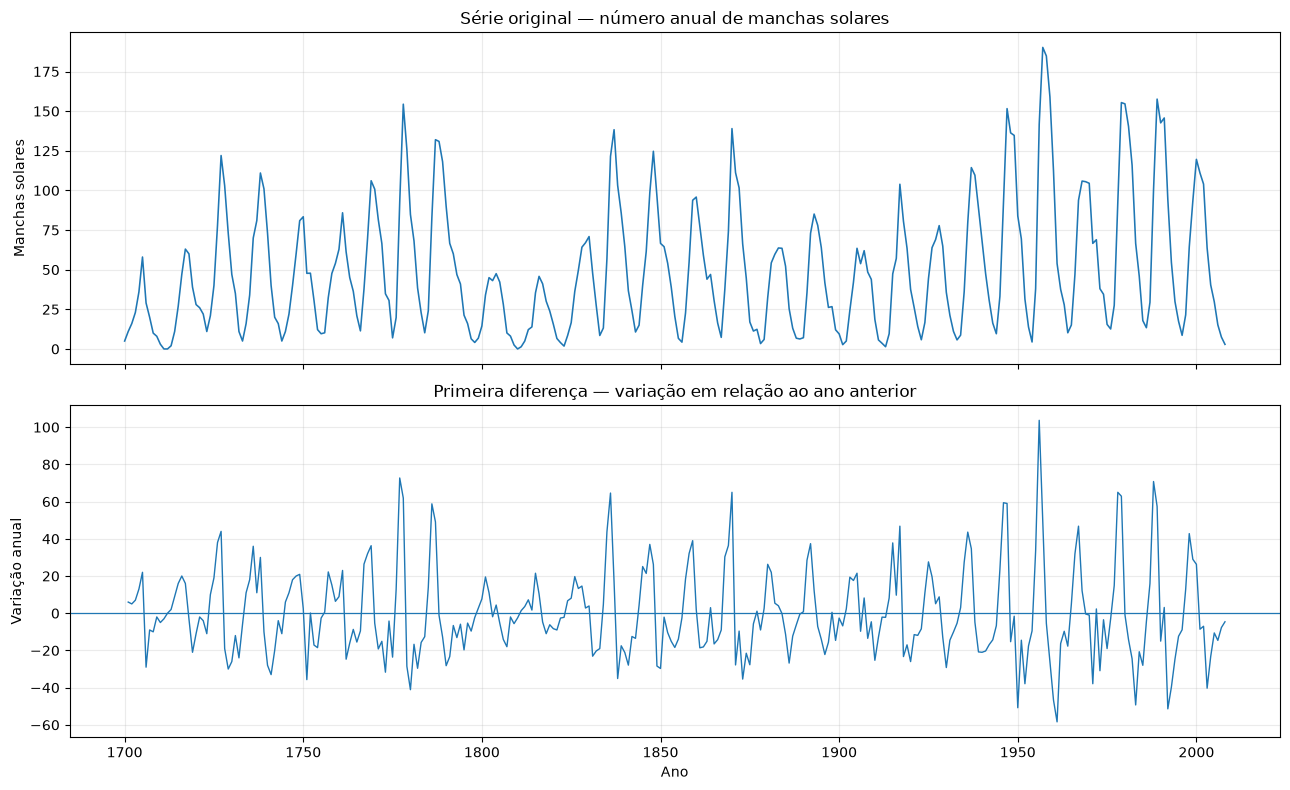

In [2]:
# Visualização da série em nível e de sua primeira diferença.
serie_dif1 = serie.diff().dropna()

fig, eixos = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
eixos[0].plot(serie.index, serie.values, linewidth=1.15)
eixos[0].set_title('Série original — número anual de manchas solares')
eixos[0].set_ylabel('Manchas solares')

eixos[1].plot(serie_dif1.index, serie_dif1.values, linewidth=1.0)
eixos[1].axhline(0, linewidth=0.9)
eixos[1].set_title('Primeira diferença — variação em relação ao ano anterior')
eixos[1].set_xlabel('Ano')
eixos[1].set_ylabel('Variação anual')
plt.tight_layout()
plt.show()

## 3. Testes ADF e KPSS: nível e primeira diferença

Executaremos os testes na série original e na primeira diferença. Na configuração principal, ambos usam constante (`regression='c'`). O ADF escolhe o número de defasagens por AIC (`autolag='AIC'`); o KPSS escolhe as defasagens por seu procedimento automático (`nlags='auto'`).

**Como ler os resultados:**

- ADF: `p < 0,05` sugere rejeitar a hipótese de raiz unitária, ao nível de 5%.
- KPSS: `p < 0,05` sugere rejeitar a hipótese de estacionariedade em torno de um nível, ao nível de 5%.
- No KPSS, a implementação informa p-valores tabulados. Quando aparece `0.10`, pode significar que o p-valor real é maior ou igual ao limite superior da tabela; não interprete esse número como um valor exato.

O nível de 5% é uma convenção para a análise, não uma fronteira absoluta entre verdadeiro e falso.

In [3]:
def executar_testes_estacionariedade(x, nome, regressao='c'):
    """Executa ADF e KPSS e devolve resultados em formato tabular."""
    x = pd.Series(x).dropna().astype(float)

    adf_resultado = adfuller(x, regression=regressao, autolag='AIC')
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        kpss_resultado = kpss(x, regression=regressao, nlags='auto')

    return {
        'Série': nome,
        'Especificação': regressao,
        'ADF — estatística': adf_resultado[0],
        'ADF — p-valor': adf_resultado[1],
        'ADF — defasagens': adf_resultado[2],
        'KPSS — estatística': kpss_resultado[0],
        'KPSS — p-valor reportado': kpss_resultado[1],
        'KPSS — defasagens': kpss_resultado[2],
        'Aviso KPSS': ' | '.join(str(a.message) for a in avisos) if avisos else ''
    }

resultados_testes = pd.DataFrame([
    executar_testes_estacionariedade(serie, 'Nível'),
    executar_testes_estacionariedade(serie_dif1, 'Primeira diferença'),
])

display(resultados_testes.round(4))

/var/folders/vx/j5k4tg5s21753jltv498n43r0000gn/T/ipykernel_69137/1230390534.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_resultado = adfuller(x, regression=regressao, autolag='AIC')
/var/folders/vx/j5k4tg5s21753jltv498n43r0000gn/T/ipykernel_69137/1230390534.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_resultado = adfuller(x, regression=regressao, aut

,Série,Especificação,ADF — estatística,ADF — p-valor,ADF — defasagens,KPSS — estatística,KPSS — p-valor reportado,KPSS — defasagens,Aviso KPSS
0,Nível,c,-2.8378,0.0531,8,0.6699,0.0163,7,kpss currently returns a plain tuple whose len...
1,Primeira diferença,c,-14.8617,0.0000,7,0.0212,0.1000,0,The test statistic is outside of the range of ...


### Interpretação orientada dos testes

Na execução de referência deste projeto, a série em nível apresenta ADF com p-valor próximo de **0,053** e KPSS com p-valor reportado próximo de **0,016**. Isso é uma combinação de evidências compatível com não estacionariedade em torno de um nível, embora o resultado do ADF fique muito próximo do limiar convencional de 5%.

Na primeira diferença, o ADF tende a rejeitar fortemente a hipótese de raiz unitária e o KPSS não tende a rejeitar a estacionariedade. Isso torna `d=1` um candidato razoável para investigar no ARIMA, mas **não prova que ARIMA(…,1,…) será o melhor modelo**.

A execução pode variar ligeiramente entre versões das bibliotecas. Use a tabela gerada no ambiente do grupo como resultado oficial e registrem as versões utilizadas.

In [4]:
# Análise de sensibilidade: incluir tendência determinística nos testes da série em nível.
# ADF e KPSS usam a especificação 'ct' para constante + tendência.
resultado_com_tendencia = pd.DataFrame([
    executar_testes_estacionariedade(serie, 'Nível — com tendência', regressao='ct')
])

display(resultado_com_tendencia[[
    'Série', 'Especificação', 'ADF — estatística', 'ADF — p-valor',
    'KPSS — estatística', 'KPSS — p-valor reportado'
]].round(4))

print('A especificação com tendência responde a uma pergunta diferente da especificação apenas com constante.')
print('Não escolha a especificação apenas porque ela produz o p-valor desejado; justifique-a pelo comportamento da série e pelo objetivo do modelo.')

/var/folders/vx/j5k4tg5s21753jltv498n43r0000gn/T/ipykernel_69137/1230390534.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_resultado = adfuller(x, regression=regressao, autolag='AIC')


,Série,Especificação,ADF — estatística,ADF — p-valor,KPSS — estatística,KPSS — p-valor reportado
0,Nível — com tendência,ct,-2.9244,0.1545,0.1158,0.1


A especificação com tendência responde a uma pergunta diferente da especificação apenas com constante.
Não escolha a especificação apenas porque ela produz o p-valor desejado; justifique-a pelo comportamento da série e pelo objetivo do modelo.


## 4. Autocorrelação (ACF) e autocorrelação parcial (PACF)

A **ACF** mede a correlação entre a série e suas versões deslocadas em diferentes quantidades de anos. A **PACF** procura isolar a associação de uma defasagem depois de controlar as defasagens intermediárias.

Os gráficos abaixo usam até 36 defasagens (três anos de observações anuais multiplicados por 12; a escolha permite observar mais de dois ciclos aproximados). As faixas tracejadas são referências aproximadas de 95% sob condições usuais; não devem ser tratadas como teste definitivo de cada defasagem.

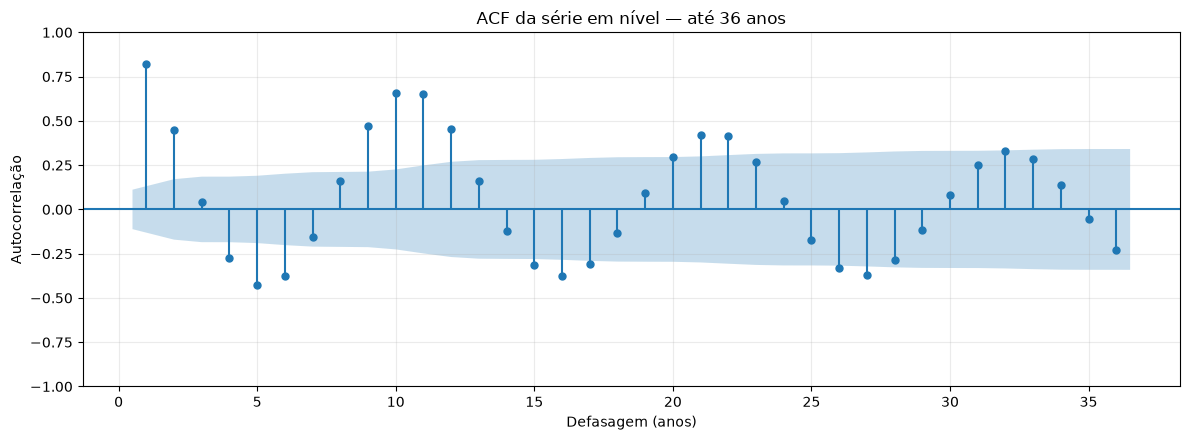

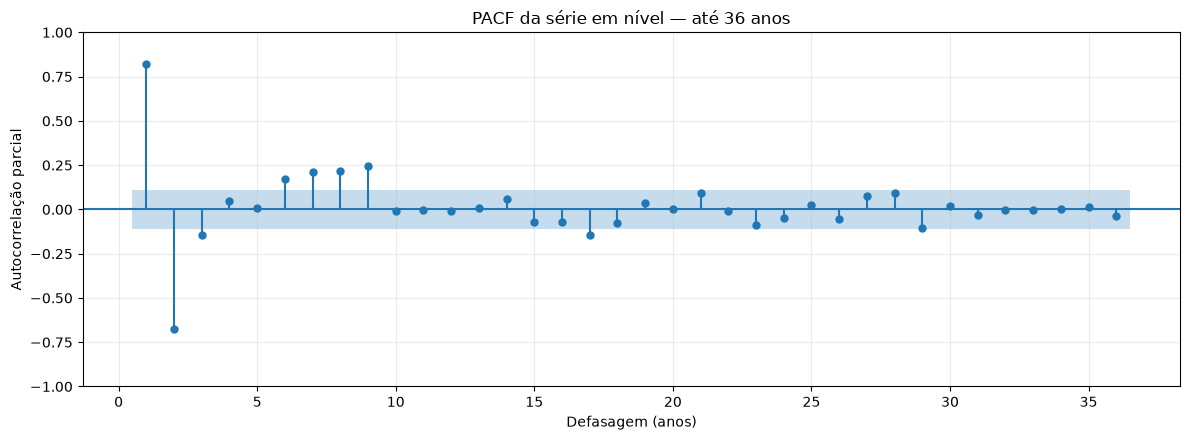

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.5))
plot_acf(serie, lags=36, zero=False, alpha=0.05, ax=ax)
ax.set_title('ACF da série em nível — até 36 anos')
ax.set_xlabel('Defasagem (anos)')
ax.set_ylabel('Autocorrelação')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))
plot_pacf(serie, lags=36, zero=False, alpha=0.05, method='ywm', ax=ax)
ax.set_title('PACF da série em nível — até 36 anos')
ax.set_xlabel('Defasagem (anos)')
ax.set_ylabel('Autocorrelação parcial')
plt.tight_layout()
plt.show()

### ACF e PACF após a primeira diferença

A comparação ajuda a verificar quanto da dependência temporal permanece depois da transformação. Uma oscilação que ainda apareça em defasagens próximas de 10–12 anos é relevante: diferenciar a série não significa eliminar automaticamente o ciclo solar.

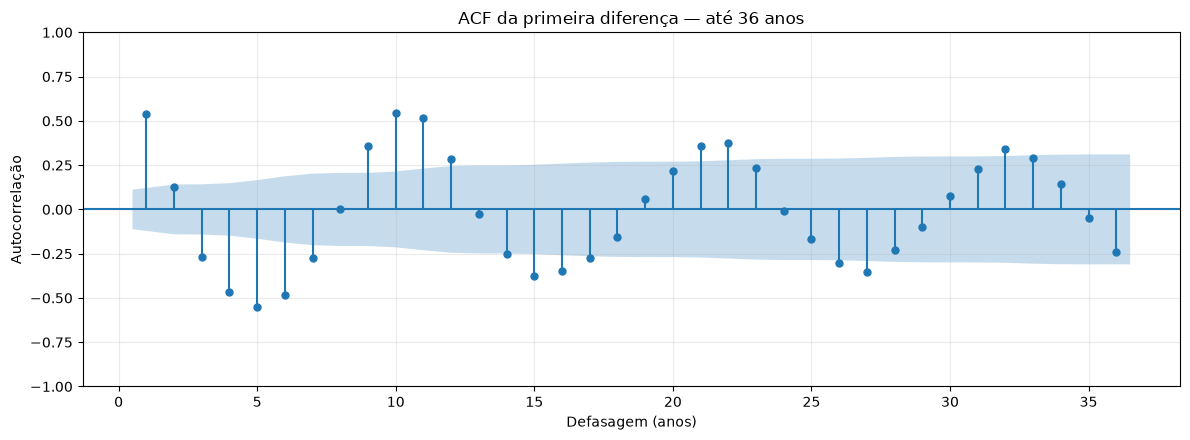

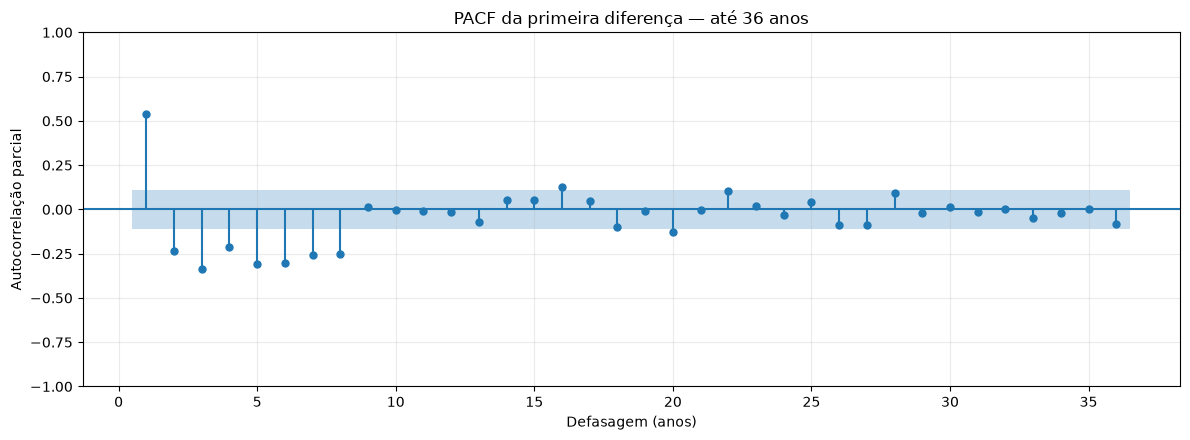

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
plot_acf(serie_dif1, lags=36, zero=False, alpha=0.05, ax=ax)
ax.set_title('ACF da primeira diferença — até 36 anos')
ax.set_xlabel('Defasagem (anos)')
ax.set_ylabel('Autocorrelação')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))
plot_pacf(serie_dif1, lags=36, zero=False, alpha=0.05, method='ywm', ax=ax)
ax.set_title('PACF da primeira diferença — até 36 anos')
ax.set_xlabel('Defasagem (anos)')
ax.set_ylabel('Autocorrelação parcial')
plt.tight_layout()
plt.show()

## 5. Análise espectral: estimativa da periodicidade dominante

O periodograma decompõe a variabilidade da série por frequência. Como existe uma observação por ano, a frequência é medida em ciclos por ano. O período correspondente é:

\[
\text{Período (anos)} = \frac{1}{\text{frequência (ciclos/ano)}}.
\]

Vamos remover uma tendência linear antes do cálculo para reduzir a influência de uma tendência de longo prazo. Essa decisão é uma forma de pré-processamento e deve ser documentada. O periodograma é uma estimativa exploratória: a duração finita da série limita a resolução das frequências, e uma periodicidade variável pode espalhar potência entre frequências próximas.

,Frequência (ciclos/ano),Período estimado (anos),Potência espectral
0,0.0906,11.0357,373.9585
1,0.0874,11.4444,277.9533
2,0.1003,9.9677,153.4978
3,0.0841,11.8846,130.1607
4,0.0097,103.0000,120.1589
5,0.0939,10.6552,97.0849
6,0.0129,77.2500,94.7085
7,0.0162,61.8000,50.4774


Período associado ao maior pico do periodograma: 11.04 anos


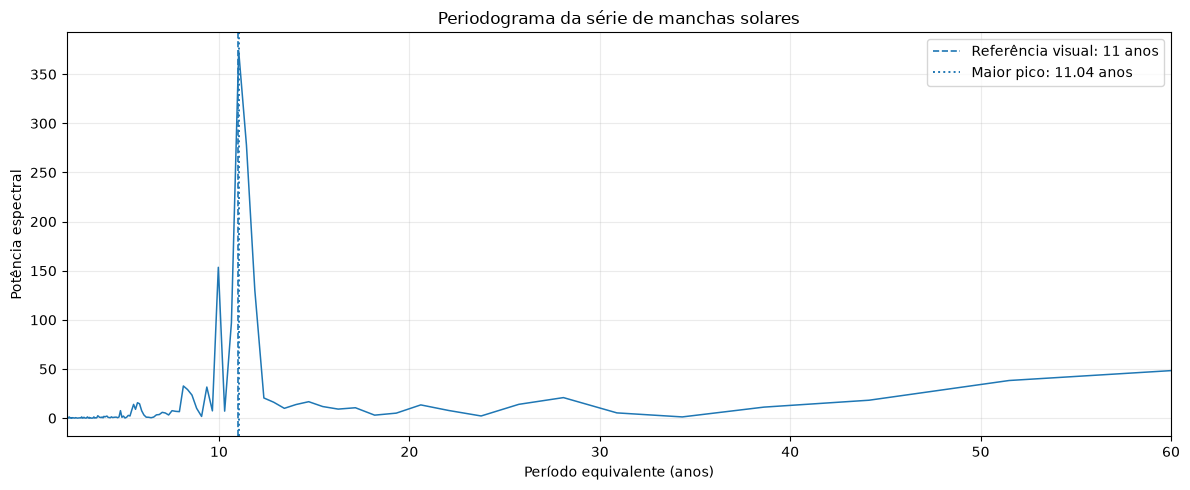

In [7]:
frequencias, potencias = periodogram(
    serie.to_numpy(),
    fs=1.0,                 # uma observação por ano
    window='hann',
    detrend='linear',       # remove tendência linear antes do espectro
    scaling='spectrum'
)

# Frequência zero não tem período finito e será excluída.
validos = frequencias > 0
freq_validas = frequencias[validos]
pot_validas = potencias[validos]
periodos = 1 / freq_validas

# Ordena os componentes por potência, do maior para o menor.
ordem = np.argsort(pot_validas)[::-1]
principais = pd.DataFrame({
    'Frequência (ciclos/ano)': freq_validas[ordem[:8]],
    'Período estimado (anos)': periodos[ordem[:8]],
    'Potência espectral': pot_validas[ordem[:8]],
})

display(principais.round(4))

indice_dominante = ordem[0]
periodo_dominante = periodos[indice_dominante]
print(f'Período associado ao maior pico do periodograma: {periodo_dominante:.2f} anos')

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(periodos, pot_validas, linewidth=1.1)
ax.axvline(11, linestyle='--', linewidth=1.2, label='Referência visual: 11 anos')
ax.axvline(periodo_dominante, linestyle=':', linewidth=1.4,
           label=f'Maior pico: {periodo_dominante:.2f} anos')
ax.set_xlim(2, min(60, periodos.max()))
ax.set_title('Periodograma da série de manchas solares')
ax.set_xlabel('Período equivalente (anos)')
ax.set_ylabel('Potência espectral')
ax.legend()
plt.tight_layout()
plt.show()

### Como interpretar o resultado espectral

Na base Statsmodels usada neste projeto, o maior pico do periodograma após remoção de tendência linear fica próximo de **11 anos** (na execução de referência, aproximadamente **11,04 anos**). Esse resultado é consistente com a periodicidade aproximada do ciclo de Schwabe.

Não interpretem 11,04 como duração exata ou constante de todos os ciclos. O valor depende da extensão da amostra, do tratamento da tendência, da janela e do método espectral. O gráfico também pode apresentar picos próximos, pois a atividade solar não é um relógio perfeitamente periódico.

## 6. Duração aproximada entre máximos locais

Como verificação complementar, o código abaixo identifica máximos locais com um critério de proeminência e distância mínima. Esses parâmetros são escolhas analíticas — não leis físicas — e podem alterar quais máximos são selecionados.

Use o resultado como uma descrição auxiliar, não como estimativa definitiva do período solar.

,Ano do máximo local,Valor anual
0,1705,58.0
1,1717,63.0
2,1727,122.0
3,1738,111.0
4,1750,83.4
5,1761,85.9
6,1769,106.1
7,1778,154.4
8,1787,132.0
9,1804,47.5


Intervalos entre máximos selecionados (anos): [12, 10, 11, 12, 11, 8, 9, 9, 17, 12, 14, 7, 11, 12, 10, 13, 10, 12, 12, 11, 9, 10, 10, 11, 11, 10, 11]
Média dos intervalos: 10.93 anos
Mediana dos intervalos: 11.00 anos


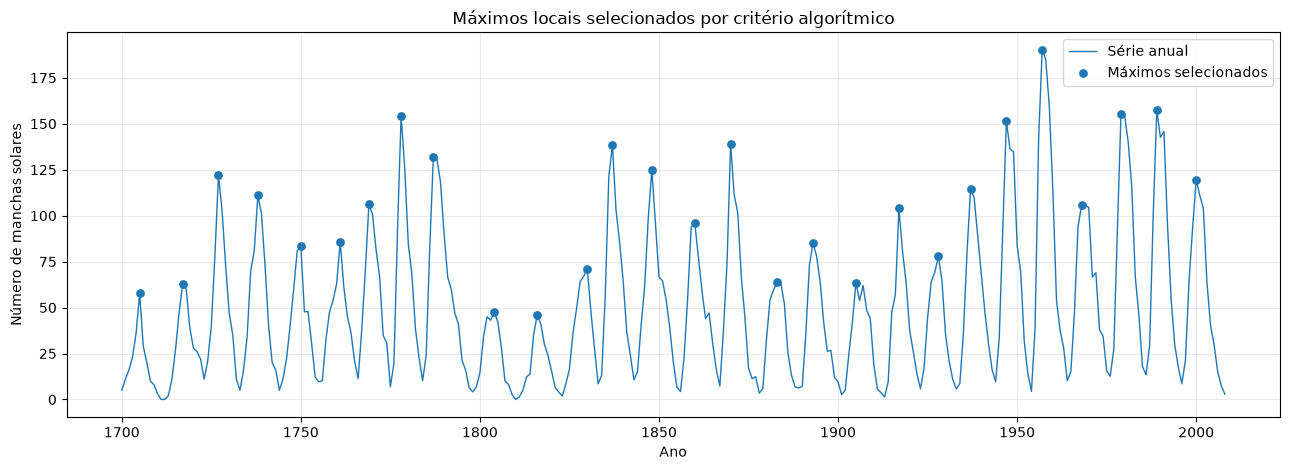

In [8]:
# Critérios heurísticos: distância mínima de 7 anos e proeminência de 20 unidades.
indices_picos, propriedades = find_peaks(
    serie.to_numpy(),
    distance=7,
    prominence=20
)
anos_picos = serie.index.to_numpy()[indices_picos]
valores_picos = serie.to_numpy()[indices_picos]

picos = pd.DataFrame({
    'Ano do máximo local': anos_picos,
    'Valor anual': valores_picos,
})
intervalos = np.diff(anos_picos)

display(picos)
if len(intervalos) > 0:
    print('Intervalos entre máximos selecionados (anos):', intervalos.tolist())
    print(f'Média dos intervalos: {intervalos.mean():.2f} anos')
    print(f'Mediana dos intervalos: {np.median(intervalos):.2f} anos')
else:
    print('Não foram identificados máximos suficientes para calcular intervalos.')

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(serie.index, serie.values, linewidth=1.0, label='Série anual')
ax.scatter(anos_picos, valores_picos, marker='o', s=28, label='Máximos selecionados')
ax.set_title('Máximos locais selecionados por critério algorítmico')
ax.set_xlabel('Ano')
ax.set_ylabel('Número de manchas solares')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Síntese para a etapa de modelagem

Com base na análise, registrem as conclusões sem transformar evidências exploratórias em certezas:

1. **Estacionariedade:** os testes em nível sugerem que a série não deve ser tratada automaticamente como estacionária em torno de uma constante. Na primeira diferença, os testes tendem a ser compatíveis com estacionariedade.
2. **Dependência temporal:** ACF e PACF mostram que as observações dependem de valores passados; as defasagens não devem ser escolhidas apenas por uma regra mecânica.
3. **Periodicidade:** a análise espectral aponta uma componente dominante próxima de 11 anos, mas o ciclo é quase periódico e varia em duração e intensidade.
4. **Consequência prática:** no próximo notebook, compararemos especificações ARIMA com diferentes ordens de diferenciação, incluindo `d=0` e `d=1`, e selecionaremos modelos usando apenas os dados de treino. A escolha final também dependerá de resíduos e desempenho fora da amostra.

**Cuidado com sazonalidade:** não é correto assumir automaticamente um SARIMA com período fixo 11 só porque a principal oscilação está próxima de 11 anos. O ciclo solar não é uma sazonalidade de calendário rigorosamente fixa.

## 8. Perguntas para discussão da equipe

Respondam com os números e gráficos produzidos na execução de vocês:

1. Qual é a hipótese nula de cada teste? Por que os p-valores do ADF e do KPSS precisam ser interpretados em sentidos opostos?
2. O que os testes sugerem sobre a série em nível? E sobre a primeira diferença?
3. A primeira diferença torna a série estatisticamente mais próxima de estacionária? Que informação do sinal original pode ser alterada pela diferenciação?
4. Que padrão vocês observam na ACF? Há indícios de oscilação em torno de defasagens próximas ao ciclo solar?
5. Qual é o período do maior pico espectral? Por que não devemos afirmar que todo ciclo solar dura exatamente esse número de anos?
6. Os máximos locais selecionados pelo algoritmo são todos inequívocos? Como a distância mínima e a proeminência alteram o resultado?
7. Com base nos resultados, por que faz sentido investigar modelos com `d=0` e `d=1` no próximo notebook?

### Modelo de registro de evidências

| Afirmação | Evidência produzida | Limitação / ressalva |
|---|---|---|
| A série apresenta dependência temporal | ACF/PACF | Correlação não implica causalidade |
| Há uma oscilação próxima de 11 anos | Periodograma e máximos locais | Ciclo quase periódico; estimativas dependem do método |
| A primeira diferença parece mais estacionária | ADF e KPSS em nível e diferença | Testes têm hipóteses e limitações distintas |

Preencham a tabela com os valores efetivamente obtidos na execução do grupo.

## 9. Próxima etapa

O **Notebook 03 — Modelagem ARIMA** deverá:

- estabelecer uma divisão cronológica de treino e teste, reservando os anos mais recentes para avaliação;
- comparar ordens candidatas de ARIMA, incluindo diferentes valores de `d` justificados pela análise;
- selecionar parâmetros sem consultar o período de teste;
- examinar AIC e diagnósticos dos resíduos;
- gerar previsões nos mesmos anos que serão usados posteriormente para comparar com o modelo de aprendizado de máquina.

A análise exploratória deste notebook pode utilizar toda a série para compreender seu comportamento histórico. Já o processo de escolha e avaliação dos modelos preditivos deve respeitar a separação temporal para evitar vazamento de dados.